### GAP

Resolver algunas cuestiones que el articulo no dejo totalmente claras:

- El paper compara su sobremuestreo con SMOTE, pero solo con una figura y sin medir cuánto mejora cada método.
- Las clases raras (SLSN-I, Ib/c) son las más interesantes en astrofísica y las que peor se clasifican.

In [6]:
import numpy as np
import pandas as pd
from pathlib import Path
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt

Path("../results").mkdir(exist_ok=True)

X = pd.read_csv("../data/features.csv")
CLASES = ["SLSN-I", "SN II", "SN IIn", "SN Ia", "SN Ib/c"]  
FEATS = [c for c in X.columns if c not in ("NAME", "CLASE")]
y = X["CLASE"].map({c: i for i, c in enumerate(CLASES)}).to_numpy()
Xf = X[FEATS].to_numpy()

print(Xf.shape, np.bincount(y))

(4902, 10) [  69  763  187 3694  189]


In [2]:
def corre_cv(seed, metodo):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
    pred_s = np.empty(len(y), dtype=int)
    for tr, te in skf.split(Xf, y):
        Xtr, ytr, Xte = Xf[tr], y[tr], Xf[te]
        cw = None
        if metodo == "pesos":
            cw = "balanced"
        elif metodo == "smote":
            Xtr, ytr = SMOTE(random_state=seed, k_neighbors=5).fit_resample(Xtr, ytr)
        elif metodo == "smote_esc":                      # SMOTE con features estandarizadas
            sc = StandardScaler().fit(Xtr)
            Xtr, ytr = SMOTE(random_state=seed, k_neighbors=5).fit_resample(sc.transform(Xtr), ytr)
            Xte = sc.transform(Xte)
        m = lgb.LGBMClassifier(boosting_type="dart", n_estimators=250, max_depth=5,
                               num_leaves=20, reg_lambda=5, class_weight=cw,
                               random_state=seed, verbose=-1).fit(Xtr, ytr)
        pred_s[te] = m.predict(Xte)
    return pred_s

Comparamos los metodos de "balanceo" de los datos para ver si podemos obtener mejores resultados dejandolos como están, dandole mas peso a las clases raras o haciendo un sobremuestreo a las clases raras.

In [3]:
filas = []
for metodo in ["ninguno", "pesos", "smote", "smote_esc"]:
    for s in range(5):
        p = corre_cv(s, metodo)
        cm_s = confusion_matrix(y, p)
        comp_s = cm_s.diagonal() / cm_s.sum(axis=1)
        pur_s = cm_s.diagonal() / cm_s.sum(axis=0)
        filas.append({"metodo": metodo, "semilla": s,
                      "accuracy": accuracy_score(y, p),
                      "F1_macro": f1_score(y, p, average="macro"),
                      **{f"comp_{c}": v for c, v in zip(CLASES, comp_s)},
                      **{f"pur_{c}": v for c, v in zip(CLASES, pur_s)}})

res_bal = pd.DataFrame(filas)
res_bal.to_csv("../results/comparacion_balanceo.csv", index=False)
cols = ["accuracy", "F1_macro", "comp_SLSN-I", "comp_SN Ib/c", "pur_SLSN-I", "pur_SN Ib/c"]
print(res_bal.groupby("metodo")[cols].agg(["mean", "std"]).round(3))

          accuracy        F1_macro        comp_SLSN-I        comp_SN Ib/c  \
              mean    std     mean    std        mean    std         mean   
metodo                                                                      
ninguno      0.876  0.002    0.522  0.012       0.154  0.019        0.141   
pesos        0.828  0.004    0.540  0.007       0.284  0.072        0.531   
smote        0.816  0.004    0.541  0.008       0.426  0.053        0.544   
smote_esc    0.820  0.004    0.545  0.006       0.380  0.036        0.564   

                 pur_SLSN-I        pur_SN Ib/c         
             std       mean    std        mean    std  
metodo                                                 
ninguno    0.029      0.447  0.043       0.574  0.040  
pesos      0.011      0.200  0.028       0.263  0.012  
smote      0.013      0.210  0.021       0.240  0.011  
smote_esc  0.033      0.223  0.019       0.234  0.010  


- Notamos que la completitud mejora al hacer sobremuestreo, sin embargo la puereza disminuye, esto quiere decir que hay un mayor probabilidad de encontrar falsos positivos.

- No hay cambios notables en en accuracy y F1, podemos apreciar de todas formas que con ningun meotodo el accuracy es mayor pero trata peor a las clases desbalanceadas.

- Un F1 de 0,54 sigue siendo cercano al 0,61 del articulo, este no es el camino para mejorar el modelo.

In [4]:
from scipy.stats import wilcoxon

def compara(a, b, col):
    pa = res_bal[res_bal.metodo == a].sort_values("semilla")[col].to_numpy()
    pb = res_bal[res_bal.metodo == b].sort_values("semilla")[col].to_numpy()
    return round((pa - pb).mean(), 3), int((pa > pb).sum()), round(wilcoxon(pa, pb).pvalue, 4)

for a, b in [("smote", "pesos"), ("smote_esc", "pesos"), ("pesos", "ninguno")]:
    for col in ["F1_macro", "comp_SLSN-I", "comp_SN Ib/c"]:
        print(a, "vs", b, col, compara(a, b, col))

smote vs pesos F1_macro (np.float64(0.001), 2, np.float64(0.8125))
smote vs pesos comp_SLSN-I (np.float64(0.142), 5, np.float64(0.0625))
smote vs pesos comp_SN Ib/c (np.float64(0.013), 3, np.float64(0.3125))
smote_esc vs pesos F1_macro (np.float64(0.005), 4, np.float64(0.3125))
smote_esc vs pesos comp_SLSN-I (np.float64(0.096), 4, np.float64(0.125))
smote_esc vs pesos comp_SN Ib/c (np.float64(0.033), 5, np.float64(0.0625))
pesos vs ninguno F1_macro (np.float64(0.018), 4, np.float64(0.125))
pesos vs ninguno comp_SLSN-I (np.float64(0.13), 5, np.float64(0.0625))
pesos vs ninguno comp_SN Ib/c (np.float64(0.39), 5, np.float64(0.0625))


El paper afirma que su sobremuestreo bayesiano mejora la clasificación frente a SMOTE y a los pesos de clase, pero solo lo muestra con una figura de las distribuciones, sin cuantificar la mejora. Esto importa porque las clases raras (SLSN-I, 1,4 % del conjunto, e Ib/c, 4 %) son las más interesantes en astrofísica y las que peor se clasifican. En esta reproduccion su completitud fue de 0,29 y 0,53, frente a 0,75 y 0,80 en el paper. Con los mismos datos puedo comparar de forma cuantitativa distintas formas de balancear las clases (sin balancear, pesos de clase y SMOTE), sin necesidad de datos externos.

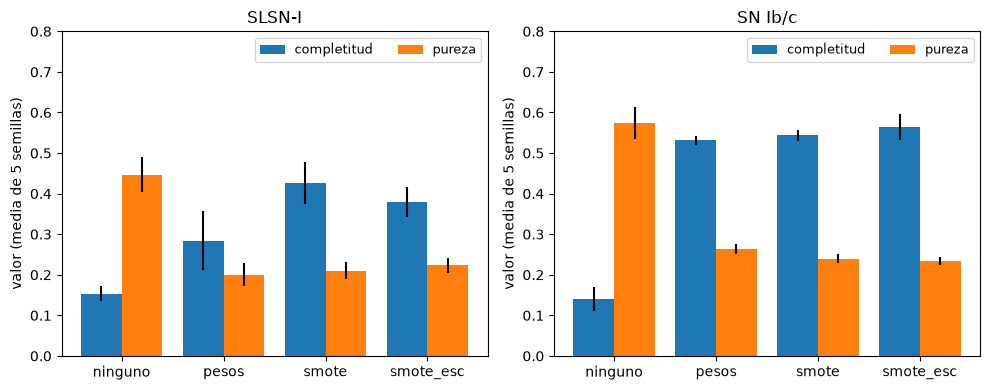

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
metodos = ["ninguno", "pesos", "smote", "smote_esc"]
g = res_bal.groupby("metodo")
for a, clase in zip(ax, ["SLSN-I", "SN Ib/c"]):
    cols = [f"comp_{clase}", f"pur_{clase}"]
    m, s = g[cols].mean().loc[metodos], g[cols].std().loc[metodos]
    x = np.arange(len(metodos))
    a.bar(x - 0.2, m[cols[0]], 0.4, yerr=s[cols[0]], label="completitud")
    a.bar(x + 0.2, m[cols[1]], 0.4, yerr=s[cols[1]], label="pureza")
    a.set_xticks(x); a.set_xticklabels(metodos)
    a.set_title(clase); a.set_ylabel("valor (media de 5 semillas)")
    a.set_ylim(0, 0.8)
    a.legend(loc="upper right", ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("../results/balanceo_comp_pureza.png", dpi=150)
plt.show()

Resultado grafico de la completitud y la pureza para las clases raras.